# Customer Churn Prediction
## Team: DataMinds

---

## Notebook 1: Data Loading, Understanding & Exploratory Data Analysis

---

## Section 1: Project Introduction

### Problem Statement

In a highly competitive market, telecom companies face a constant struggle to keep their subscribers. When customers **churn** — meaning they cancel their service or switch to a competitor — the company loses not only the immediate revenue from that customer but also the long-term potential value of that relationship.

It is significantly more expensive (often **5 to 7 times more**) to acquire a new customer than it is to retain an existing one. The business problem is:

> **How can we identify which customers are likely to leave _before_ they actually do?**

By predicting churn, the company can move from a **reactive** state (losing customers) to a **proactive** state (saving them).

### Objectives

1. Load and merge three separate telecom datasets using `customerID` as the common key.
2. Understand the structure and quality of the merged dataset.
3. Perform comprehensive Exploratory Data Analysis (EDA).
4. Identify key factors associated with customer churn.
5. Save the cleaned dataset for use in Notebook 2.

### Why Customer Churn Prediction Matters

| Variable Type | Examples | Business Relevance |
|---|---|---|
| Behavioral | Tenure, MonthlyCharges | History and pricing pressure indicators |
| Service Choices | InternetService, TechSupport | Stickiness of the customer ecosystem |
| Contract/Billing | Contract, PaymentMethod | Nature of the customer relationship |
| Demographics | SeniorCitizen, Partner | Audience profile for targeted offers |

### Project Workflow

```
Notebook 1                               Notebook 2
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Load Data → Merge → EDA → Save CSV  →  Preprocess → RFE → GLM
                                          → ROC → Evaluate → Save Model
```

---
## Section 2: Importing Libraries

In [1]:
# Core data manipulation and numerical libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Utility
import os
import warnings
warnings.filterwarnings('ignore')

# ── Presentation Style ──────────────────────────────────────────
plt.rcParams['figure.dpi']     = 100
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize']= 11
plt.rcParams['ytick.labelsize']= 11
plt.rcParams['font.family']    = 'DejaVu Sans'

# Consistent colour palette across EDA
PALETTE       = ['#2196F3', '#F44336']   # Blue = No Churn, Red = Churn
PALETTE_MULTI = 'Set2'
EXPORT_DPI    = 300

# Output directories (relative to notebooks/ — adjust if running from project root)
BASE_REPORT_DIR = '..' if os.path.exists(os.path.join('..', 'data')) else '.'
GRAPH_DIR = os.path.join(BASE_REPORT_DIR, 'reports', 'important_graphs')
os.makedirs(GRAPH_DIR, exist_ok=True)

print("Libraries loaded successfully.")

Libraries loaded successfully.


---
## Section 3: Dataset Loading

The project uses **three CSV files** stored in `data/raw/`. Each file captures a different dimension of the customer's profile:

| File | Description |
|---|---|
| `churn_data.csv` | Account lifecycle, billing, contract, and target (`Churn`) |
| `customer_data.csv` | Demographics: gender, age bracket, partner/dependent status |
| `internet_data.csv` | Service subscriptions: internet type and add-ons |

In [2]:
# ── Load the three raw datasets ──────────────────────────────────
# Auto-detect data path (supports local folder structure and flat Google Colab upload)
if os.path.exists(os.path.join('..', 'data', 'raw', 'churn_data.csv')):
    DATA_DIR = os.path.join('..', 'data', 'raw')
elif os.path.exists(os.path.join('data', 'raw', 'churn_data.csv')):
    DATA_DIR = os.path.join('data', 'raw')
elif os.path.exists('churn_data.csv'):
    DATA_DIR = '.'
else:
    DATA_DIR = os.path.join('..', 'data', 'raw')

churn_data    = pd.read_csv(os.path.join(DATA_DIR, 'churn_data.csv'))
customer_data = pd.read_csv(os.path.join(DATA_DIR, 'customer_data.csv'))
internet_data = pd.read_csv(os.path.join(DATA_DIR, 'internet_data.csv'))

print(f"churn_data    shape: {churn_data.shape}")
print(f"customer_data shape: {customer_data.shape}")
print(f"internet_data shape: {internet_data.shape}")

churn_data    shape: (7043, 9)
customer_data shape: (7043, 5)
internet_data shape: (7043, 9)


In [3]:
# Preview churn_data
print("=== churn_data : First 5 rows ===")
churn_data.head()

=== churn_data : First 5 rows ===


,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,1,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,34,Yes,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,2,Yes,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,45,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,2,Yes,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Preview customer_data
print("=== customer_data : First 5 rows ===")
customer_data.head()

=== customer_data : First 5 rows ===


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


In [5]:
# Preview internet_data
print("=== internet_data : First 5 rows ===")
internet_data.head()

=== internet_data : First 5 rows ===


,customerID,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,No phone service,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,No,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,No,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,No phone service,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,No,Fiber optic,No,No,No,No,No,No


In [6]:
# ── Column names and data types ───────────────────────────────────
for name, df in [('churn_data', churn_data),
                  ('customer_data', customer_data),
                  ('internet_data', internet_data)]:
    print(f"\n{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    df.info()


  churn_data
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   tenure            7043 non-null   int64  
 2   PhoneService      7043 non-null   str    
 3   Contract          7043 non-null   str    
 4   PaperlessBilling  7043 non-null   str    
 5   PaymentMethod     7043 non-null   str    
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   str    
 8   Churn             7043 non-null   str    
dtypes: float64(1), int64(1), str(7)
memory usage: 495.3 KB

  customer_data
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     7043 non-null   str  
 1   gender         7043 non-null   str  
 2   SeniorCitizen  7043 non-null 

---
## Section 4: Data Understanding and Merging

### Merging Logic

All three datasets share the `customerID` column as a unique key. We perform two sequential **inner joins**:

1. `churn_data` ⊕ `customer_data` → `df1`  
2. `df1` ⊕ `internet_data` → `telecom`

An inner join ensures we only retain records that exist in **all three** datasets.

In [7]:
# Step 1: Merge churn_data with customer_data on customerID
df1 = pd.merge(churn_data, customer_data, how='inner', on='customerID')
print(f"After first merge : {df1.shape}")
df1.head()

After first merge : (7043, 13)


,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,1,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,Female,0,Yes,No
1,5575-GNVDE,34,Yes,One year,No,Mailed check,56.95,1889.5,No,Male,0,No,No
2,3668-QPYBK,2,Yes,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Male,0,No,No
3,7795-CFOCW,45,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Male,0,No,No
4,9237-HQITU,2,Yes,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Female,0,No,No


In [8]:
# Step 2: Merge df1 with internet_data on customerID
telecom = pd.merge(df1, internet_data, how='inner', on='customerID')
print(f"Final merged dataset : {telecom.shape}")
telecom.head()

Final merged dataset : (7043, 21)


,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,gender,...,Partner,Dependents,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,1,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,Female,...,Yes,No,No phone service,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,34,Yes,One year,No,Mailed check,56.95,1889.5,No,Male,...,No,No,No,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,2,Yes,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Male,...,No,No,No,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,45,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Male,...,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,2,Yes,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Female,...,No,No,No,Fiber optic,No,No,No,No,No,No


In [9]:
# ── Dataset overview ──────────────────────────────────────────────
print("Shape :", telecom.shape)
print("\nColumns:", list(telecom.columns))

Shape : (7043, 21)

Columns: ['customerID', 'tenure', 'PhoneService', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']


In [10]:
# Detailed data types and non-null counts
telecom.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   tenure            7043 non-null   int64  
 2   PhoneService      7043 non-null   str    
 3   Contract          7043 non-null   str    
 4   PaperlessBilling  7043 non-null   str    
 5   PaymentMethod     7043 non-null   str    
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   str    
 8   Churn             7043 non-null   str    
 9   gender            7043 non-null   str    
 10  SeniorCitizen     7043 non-null   int64  
 11  Partner           7043 non-null   str    
 12  Dependents        7043 non-null   str    
 13  MultipleLines     7043 non-null   str    
 14  InternetService   7043 non-null   str    
 15  OnlineSecurity    7043 non-null   str    
 16  OnlineBackup      7043 non-null   str    
 17  Device

In [11]:
# Numerical summary statistics
telecom.describe()

,tenure,MonthlyCharges,SeniorCitizen
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,0.162147
std,24.559481,30.090047,0.368612
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,0.000000
50%,29.000000,70.350000,0.000000
75%,55.000000,89.850000,0.000000
max,72.000000,118.750000,1.000000


In [12]:
# Categorical summary statistics
telecom.describe(include='O')

,customerID,PhoneService,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn,gender,Partner,Dependents,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,3,2,4,6531,2,2,2,2,3,3,3,3,3,3,3,3
top,7590-VHVEG,Yes,Month-to-month,Yes,Electronic check,20.2,No,Male,No,No,No,Fiber optic,No,No,No,No,No,No
freq,1,6361,3875,4171,2365,11,5174,3555,3641,4933,3390,3096,3498,3088,3095,3473,2810,2785


In [13]:
# ── Duplicate check ───────────────────────────────────────────────
print(f"Duplicate rows: {telecom.duplicated().sum()}")
print(f"Unique CustomerIDs: {telecom['customerID'].nunique()}")

Duplicate rows: 0
Unique CustomerIDs: 7043


In [14]:
# ── Missing value check ───────────────────────────────────────────
missing_pct = round(100 * (telecom.isnull().sum() / len(telecom)), 2)
print("Missing value percentage per column:")
print(missing_pct[missing_pct > 0] if (missing_pct > 0).any() else "No missing values found in any column.")

Missing value percentage per column:
No missing values found in any column.


> **Note:** `TotalCharges` is stored as an object (string) due to whitespace entries for new customers with 0 tenure. This will be handled during preprocessing in Notebook 2.

In [15]:
# ── Target variable understanding ─────────────────────────────────
churn_counts = telecom['Churn'].value_counts()
churn_pct    = telecom['Churn'].value_counts(normalize=True) * 100

print("Churn Value Counts:")
print(churn_counts)
print("\nChurn Percentage:")
print(churn_pct.round(2))

Churn Value Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [16]:
# ── Save merged dataset as preprocessed CSV ───────────────────────
# Save preprocessed dataset (supports local structure and Colab)
if os.path.exists(os.path.join('..', 'data')):
    PREPROCESSED_DIR = os.path.join('..', 'data', 'preprocessed')
elif os.path.exists('data'):
    PREPROCESSED_DIR = os.path.join('data', 'preprocessed')
else:
    PREPROCESSED_DIR = '.'
os.makedirs(PREPROCESSED_DIR, exist_ok=True)
telecom.to_csv(os.path.join(PREPROCESSED_DIR, 'telecom_cleaned.csv'), index=False)
print("Merged dataset saved to data/preprocessed/telecom_cleaned.csv")

Merged dataset saved to data/preprocessed/telecom_cleaned.csv

---
## Section 5 & 6: Exploratory Data Analysis

We perform EDA in four logical groups:
1. **Target variable** – Overall churn distribution  
2. **Demographics** – Gender, SeniorCitizen, Partner, Dependents  
3. **Account features** – Contract, Payment, Billing, Tenure  
4. **Services** – PhoneService, MultipleLines, InternetService, Add-ons  

Every important chart is exported at 300 DPI to `reports/important_graphs/`.

### 5.1 Overall Churn Distribution

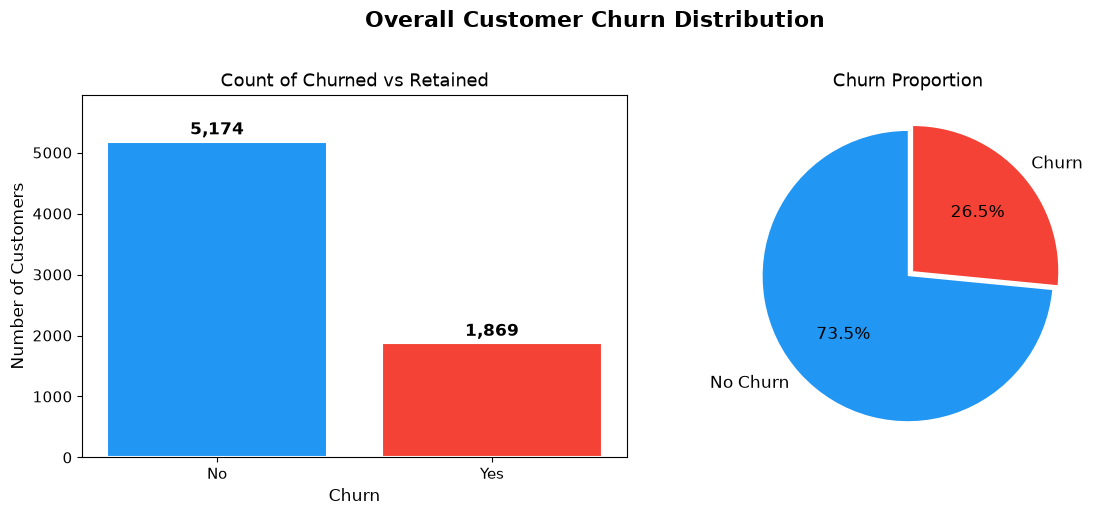

Saved: 01_churn_distribution.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Overall Customer Churn Distribution', fontsize=16, fontweight='bold', y=1.02)

# Count bar
churn_counts_plot = telecom['Churn'].value_counts()
bars = axes[0].bar(churn_counts_plot.index, churn_counts_plot.values,
                   color=PALETTE, edgecolor='white', linewidth=1.5)
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 60,
                 f'{int(bar.get_height()):,}', ha='center', va='bottom', fontsize=12, fontweight='bold')
axes[0].set_title('Count of Churned vs Retained', fontsize=13)
axes[0].set_xlabel('Churn', fontsize=12)
axes[0].set_ylabel('Number of Customers', fontsize=12)
axes[0].set_ylim(0, churn_counts_plot.max() * 1.15)

# Pie chart
churn_pie = telecom['Churn'].value_counts()
axes[1].pie(churn_pie.values, labels=['No Churn', 'Churn'],
            autopct='%1.1f%%', startangle=90,
            colors=PALETTE, explode=[0, 0.05],
            textprops={'fontsize': 12})
axes[1].set_title('Churn Proportion', fontsize=13)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, '01_churn_distribution.png'), dpi=EXPORT_DPI, bbox_inches='tight')
plt.show()
print("Saved: 01_churn_distribution.png")

**Interpretation:**  
- **What the graph shows:** Count and percentage split between customers who churned (Yes) and those who stayed (No).  
- **Pattern observed:** Approximately **26.5%** of customers churned, while **73.5%** were retained — a moderate class imbalance of roughly 3:1.  
- **Why it matters:** This baseline churn rate of 26.5% is a significant business concern. It tells us that more than 1 in 4 customers left, and that our model must be tuned specifically to capture this minority class rather than defaulting to predicting "No Churn" all the time.

### 5.2 Univariate Analysis — Demographic Categorical Variables

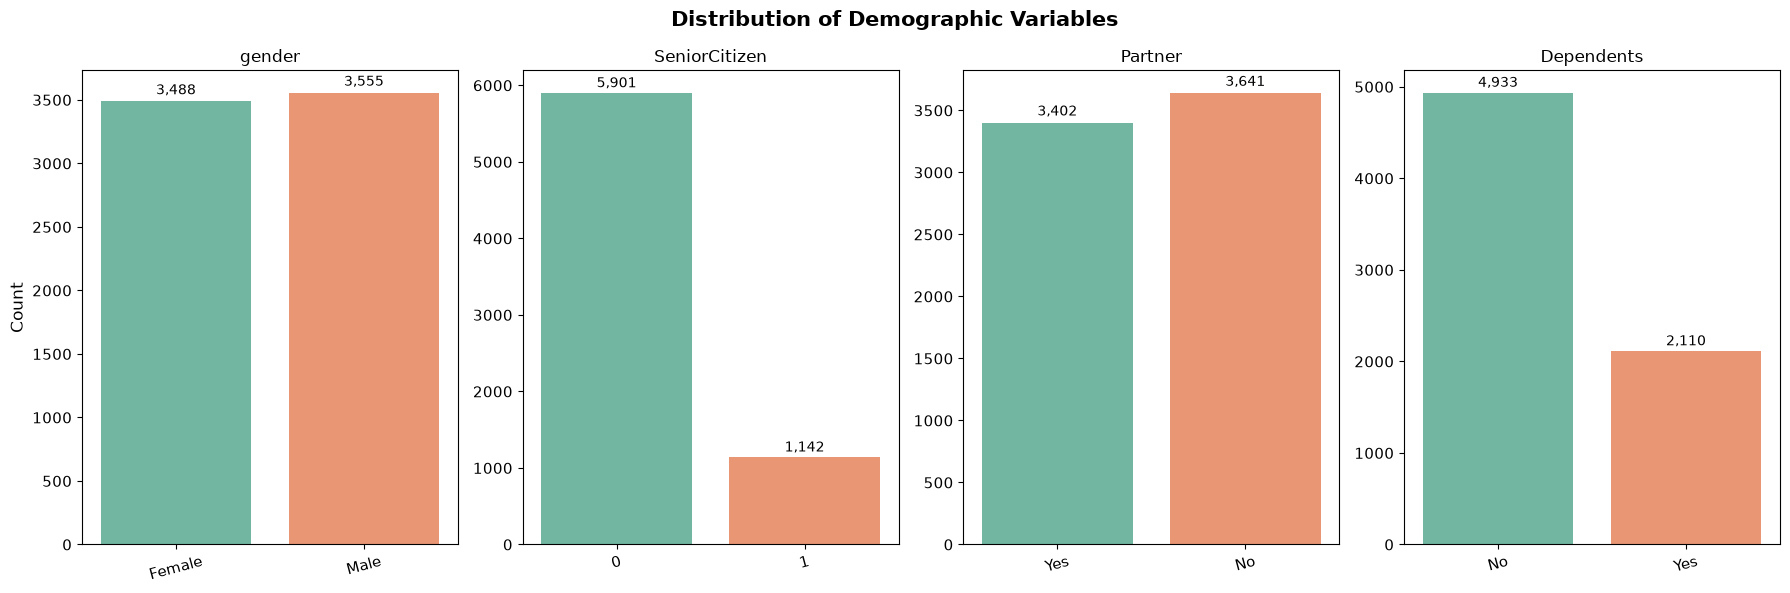

In [18]:
cat_demo = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']

fig, axes = plt.subplots(1, 4, figsize=(18, 6))
fig.suptitle('Distribution of Demographic Variables', fontsize=15, fontweight='bold')

for i, col in enumerate(cat_demo):
    sns.countplot(x=col, data=telecom, ax=axes[i], palette=PALETTE_MULTI)
    for bar in axes[i].patches:
        h = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2, h + 30,
                     f'{int(h):,}', ha='center', va='bottom', fontsize=10)
    axes[i].set_title(f'{col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count' if i == 0 else '')
    axes[i].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

### 5.3 Univariate Analysis — Account & Billing Variables

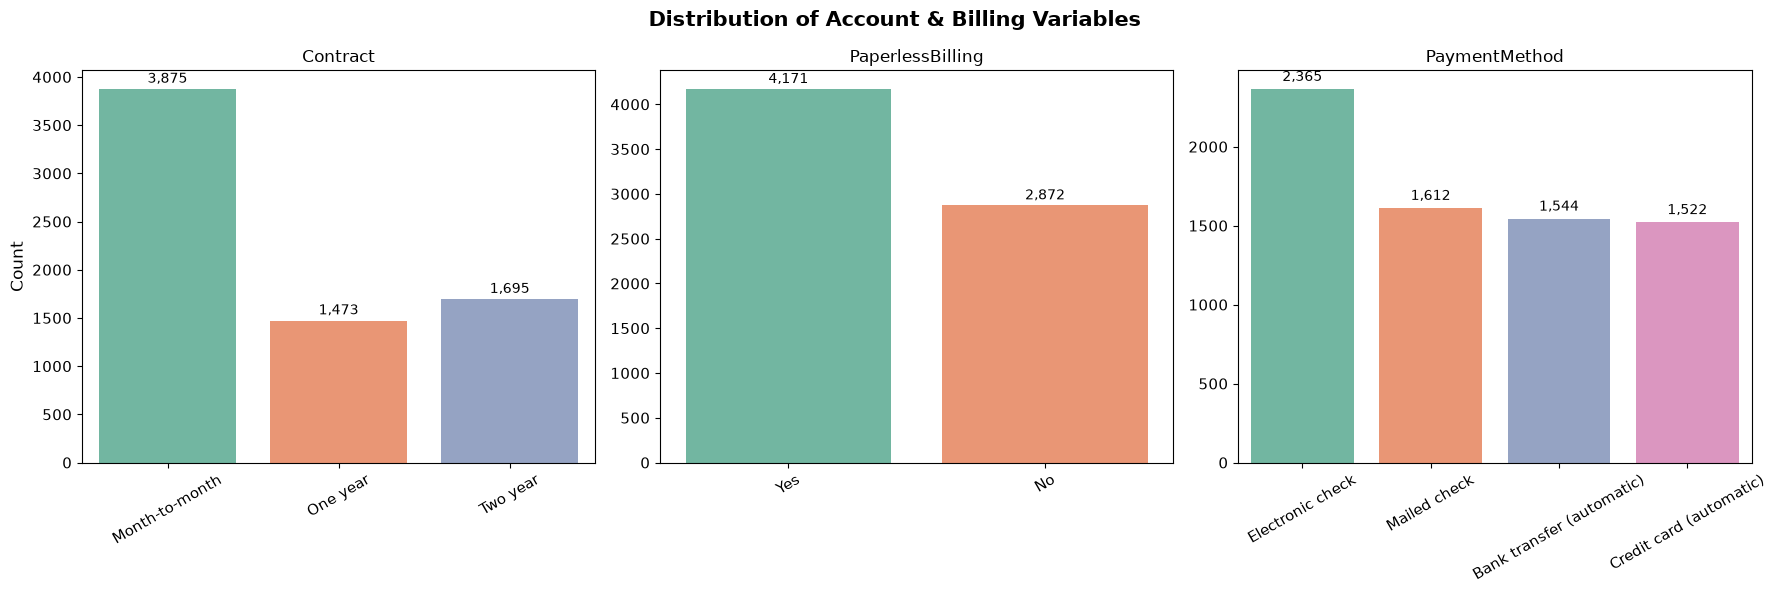

In [19]:
cat_account = ['Contract', 'PaperlessBilling', 'PaymentMethod']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Distribution of Account & Billing Variables', fontsize=15, fontweight='bold')

for i, col in enumerate(cat_account):
    sns.countplot(x=col, data=telecom, ax=axes[i], palette=PALETTE_MULTI)
    for bar in axes[i].patches:
        h = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2, h + 30,
                     f'{int(h):,}', ha='center', va='bottom', fontsize=10)
    axes[i].set_title(f'{col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count' if i == 0 else '')
    axes[i].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### 5.4 Univariate Analysis — Service Variables

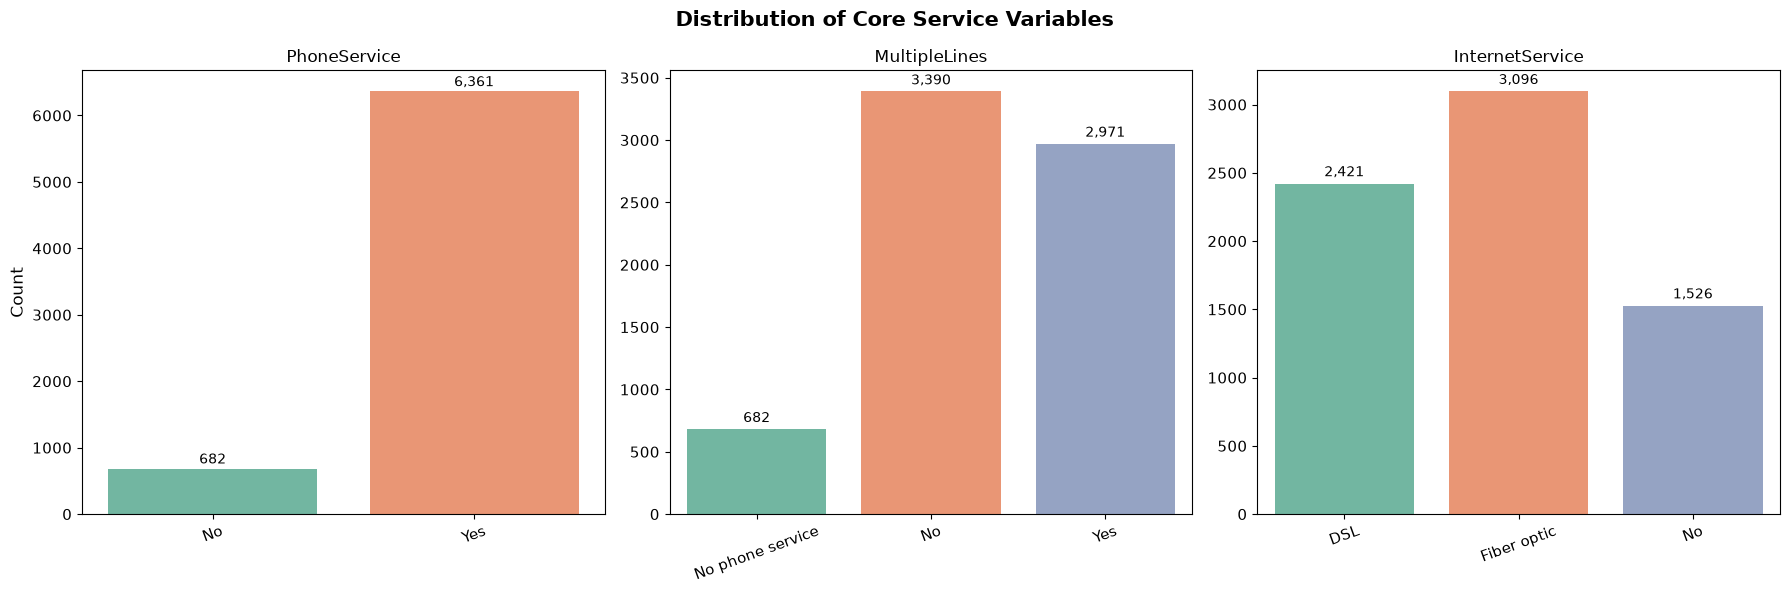

In [20]:
cat_services1 = ['PhoneService', 'MultipleLines', 'InternetService']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Distribution of Core Service Variables', fontsize=15, fontweight='bold')

for i, col in enumerate(cat_services1):
    sns.countplot(x=col, data=telecom, ax=axes[i], palette=PALETTE_MULTI)
    for bar in axes[i].patches:
        h = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2, h + 30,
                     f'{int(h):,}', ha='center', va='bottom', fontsize=10)
    axes[i].set_title(f'{col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count' if i == 0 else '')
    axes[i].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

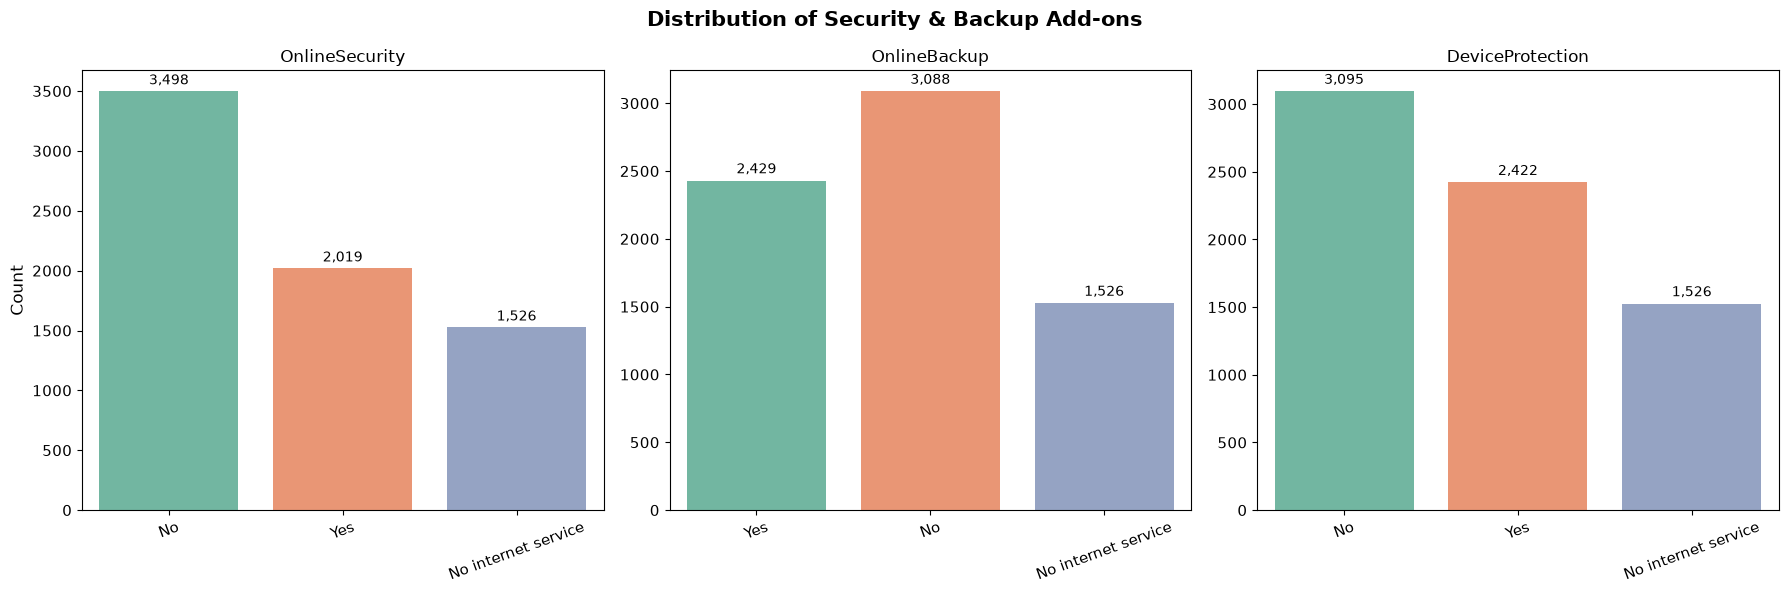

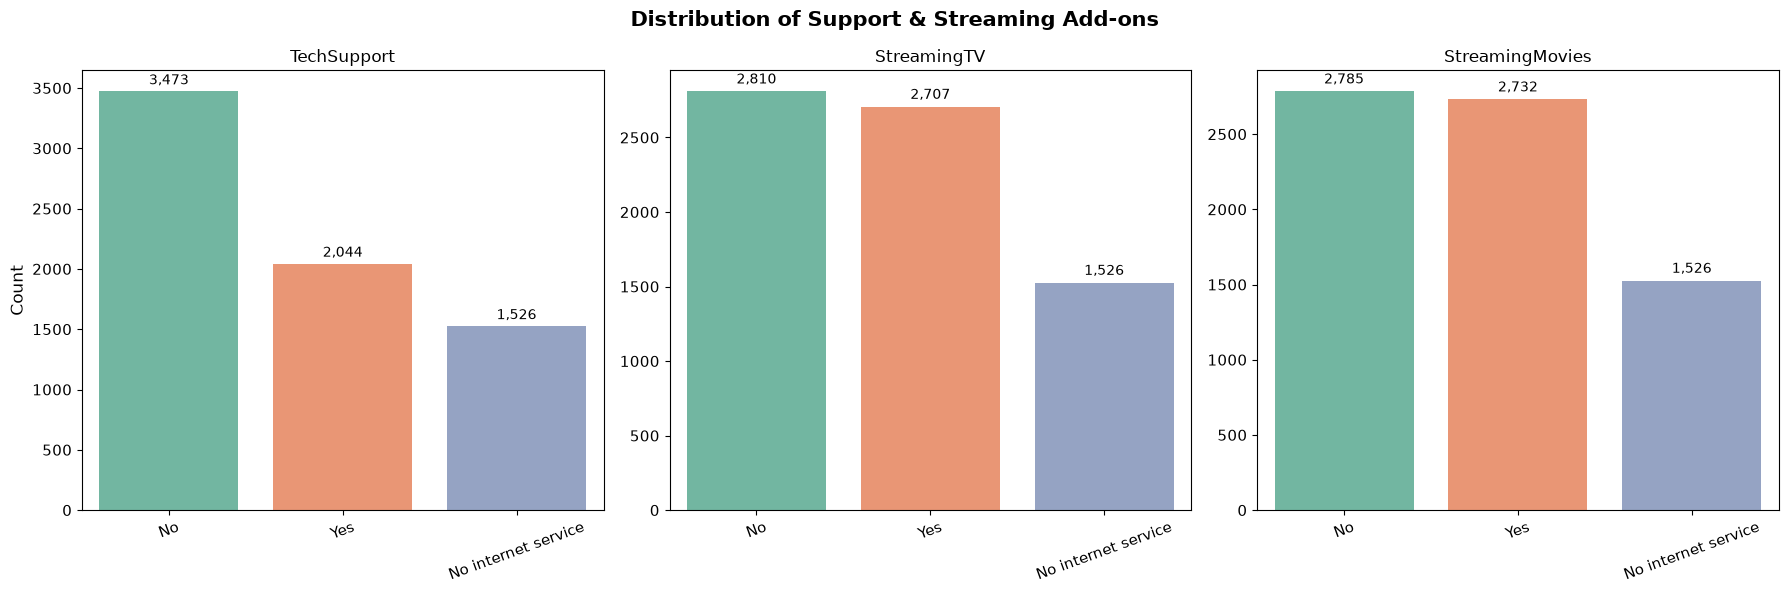

In [21]:
cat_services2 = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection']
cat_services3 = ['TechSupport', 'StreamingTV', 'StreamingMovies']

for cat_group, group_name in [(cat_services2, 'Security & Backup Add-ons'),
                               (cat_services3, 'Support & Streaming Add-ons')]:
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(f'Distribution of {group_name}', fontsize=15, fontweight='bold')
    for i, col in enumerate(cat_group):
        sns.countplot(x=col, data=telecom, ax=axes[i], palette=PALETTE_MULTI)
        for bar in axes[i].patches:
            h = bar.get_height()
            axes[i].text(bar.get_x() + bar.get_width()/2, h + 30,
                         f'{int(h):,}', ha='center', va='bottom', fontsize=10)
        axes[i].set_title(f'{col}', fontsize=12)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('Count' if i == 0 else '')
        axes[i].tick_params(axis='x', rotation=20)
    plt.tight_layout()
    plt.show()

### 5.5 Bivariate Analysis — Tenure vs Churn (Box Plot)

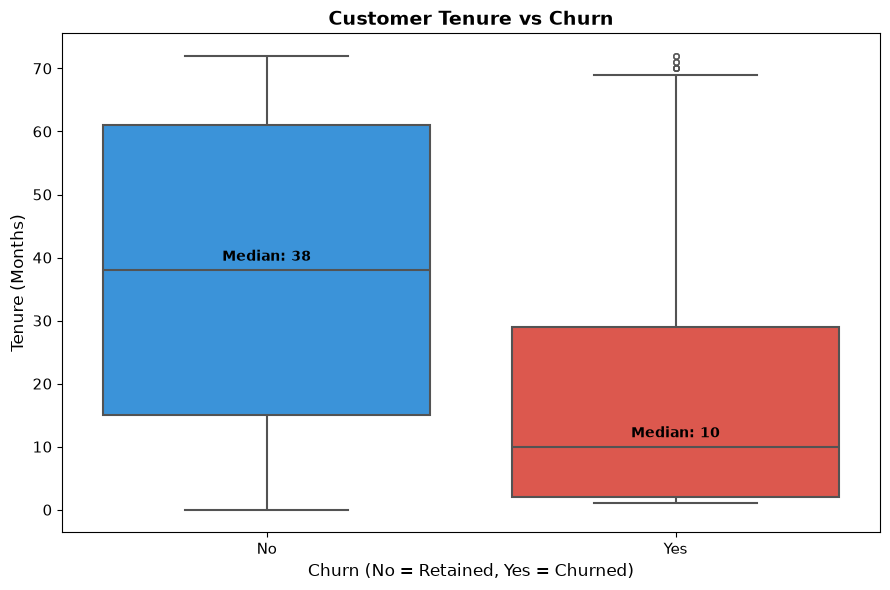

Saved: 02_tenure_vs_churn.png


In [22]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(x='Churn', y='tenure', data=telecom, palette=PALETTE, ax=ax,
            linewidth=1.5, flierprops=dict(marker='o', markersize=4, alpha=0.4))
ax.set_title('Customer Tenure vs Churn', fontsize=14, fontweight='bold')
ax.set_xlabel('Churn (No = Retained, Yes = Churned)', fontsize=12)
ax.set_ylabel('Tenure (Months)', fontsize=12)

# Annotate medians
for i, churn_val in enumerate(['No', 'Yes']):
    median_val = telecom[telecom['Churn'] == churn_val]['tenure'].median()
    ax.text(i, median_val + 1.5, f'Median: {int(median_val)}',
            ha='center', fontsize=10, color='black', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, '02_tenure_vs_churn.png'), dpi=EXPORT_DPI, bbox_inches='tight')
plt.show()
print("Saved: 02_tenure_vs_churn.png")

**Interpretation:**  
- **What the graph shows:** Distribution of customer tenure (in months) separated by churn status.  
- **Pattern observed:** Retained customers have a **median tenure of ~38 months**, while churned customers have a much lower **median of ~10 months**. 75% of all churn happens before the customer reaches the 29-month mark.  
- **Why it matters:** Churn risk is heavily concentrated in a customer's **first year**. Early retention strategies — such as onboarding discounts or proactive check-ins — are essential for new subscribers.

### 5.6 Monthly Charges vs Churn (Box Plot)

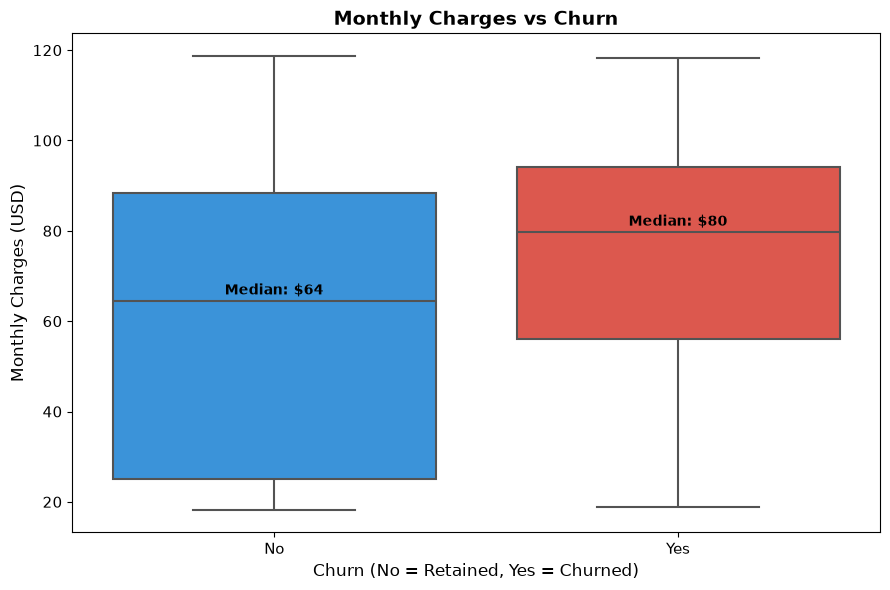

Saved: 03_monthly_charges_vs_churn.png


In [23]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(x='Churn', y='MonthlyCharges', data=telecom, palette=PALETTE, ax=ax,
            linewidth=1.5, flierprops=dict(marker='o', markersize=4, alpha=0.4))
ax.set_title('Monthly Charges vs Churn', fontsize=14, fontweight='bold')
ax.set_xlabel('Churn (No = Retained, Yes = Churned)', fontsize=12)
ax.set_ylabel('Monthly Charges (USD)', fontsize=12)

for i, churn_val in enumerate(['No', 'Yes']):
    median_val = telecom[telecom['Churn'] == churn_val]['MonthlyCharges'].median()
    ax.text(i, median_val + 1.5, f'Median: ${median_val:.0f}',
            ha='center', fontsize=10, color='black', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, '03_monthly_charges_vs_churn.png'), dpi=EXPORT_DPI, bbox_inches='tight')
plt.show()
print("Saved: 03_monthly_charges_vs_churn.png")

**Interpretation:**  
- **What the graph shows:** Monthly billing amounts for retained vs churned customers.  
- **Pattern observed:** Churned customers pay a **significantly higher median monthly charge (~$80)** compared to retained customers (~$64). The IQR for churned customers is tightly compressed between $56–$94.  
- **Why it matters:** Higher monthly bills are a core driver of churn. Premium pricing tiers without perceived value cause customers to seek cheaper alternatives. Targeted loyalty discounts for high-bill customers could reduce this risk.

### 5.7 Contract Type vs Churn

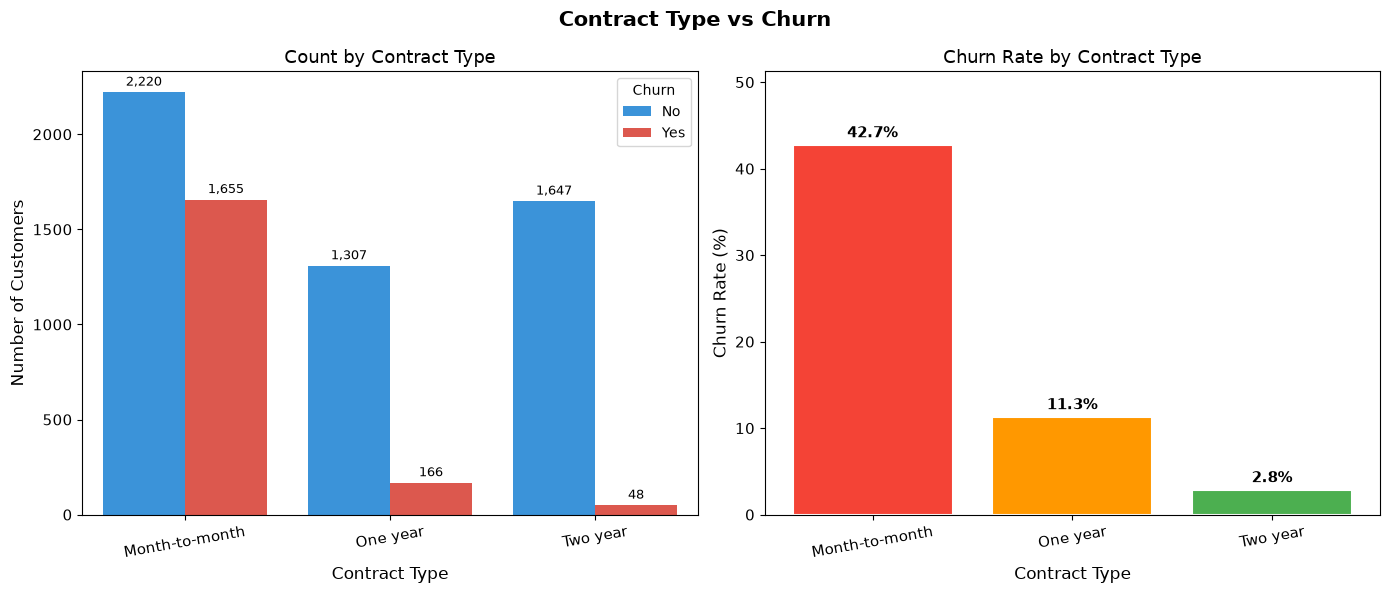

Saved: 04_contract_vs_churn.png


In [24]:
# Churn rate by contract type
contract_churn = telecom.groupby('Contract')['Churn'].value_counts(normalize=True).mul(100).rename('Percentage').reset_index()
contract_churn_yes = contract_churn[contract_churn['Churn'] == 'Yes']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Contract Type vs Churn', fontsize=15, fontweight='bold')

# Grouped bar
sns.countplot(x='Contract', hue='Churn', data=telecom, ax=axes[0], palette=PALETTE)
for bar in axes[0].patches:
    h = bar.get_height()
    if h > 0:
        axes[0].text(bar.get_x() + bar.get_width()/2, h + 20, f'{int(h):,}',
                     ha='center', va='bottom', fontsize=9)
axes[0].set_title('Count by Contract Type', fontsize=13)
axes[0].set_xlabel('Contract Type')
axes[0].set_ylabel('Number of Customers')
axes[0].legend(title='Churn')
axes[0].tick_params(axis='x', rotation=10)

# Churn rate bar
contract_order = ['Month-to-month', 'One year', 'Two year']
churn_rates = [telecom[telecom['Contract'] == c]['Churn'].eq('Yes').mean() * 100 for c in contract_order]
colors = ['#F44336', '#FF9800', '#4CAF50']
bars2 = axes[1].bar(contract_order, churn_rates, color=colors, edgecolor='white', linewidth=1.5)
for bar, rate in zip(bars2, churn_rates):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{rate:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[1].set_title('Churn Rate by Contract Type', fontsize=13)
axes[1].set_xlabel('Contract Type')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_ylim(0, max(churn_rates) * 1.2)
axes[1].tick_params(axis='x', rotation=10)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, '04_contract_vs_churn.png'), dpi=EXPORT_DPI, bbox_inches='tight')
plt.show()
print("Saved: 04_contract_vs_churn.png")

**Interpretation:**  
- **What the graph shows:** Churn counts and churn rates broken down by contract type (Month-to-month, One year, Two year).  
- **Pattern observed:** Month-to-month customers churn at a rate of approximately **42%**, compared to only **~11%** for one-year and **~3%** for two-year contracts.  
- **Why it matters:** Contract type is one of the strongest predictors of churn. Converting month-to-month customers to annual or bi-annual contracts through loyalty incentives could dramatically reduce attrition.

### 5.8 Internet Service vs Churn

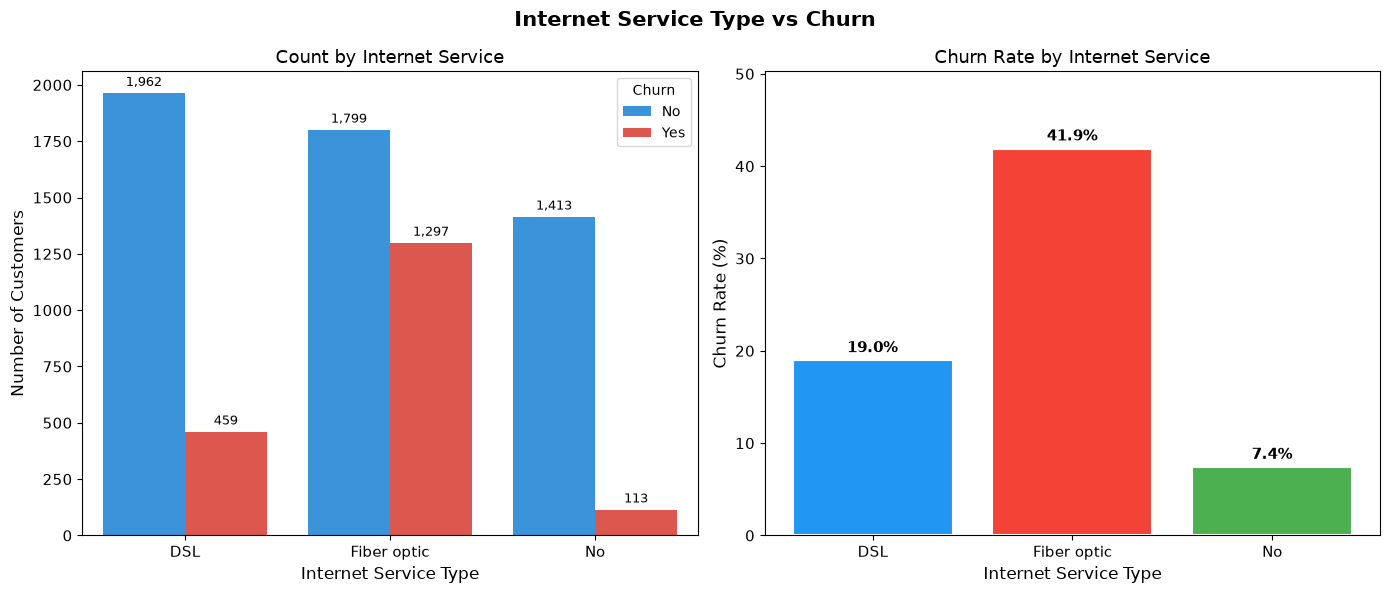

Saved: 05_internet_service_vs_churn.png


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Internet Service Type vs Churn', fontsize=15, fontweight='bold')

sns.countplot(x='InternetService', hue='Churn', data=telecom, ax=axes[0], palette=PALETTE)
for bar in axes[0].patches:
    h = bar.get_height()
    if h > 0:
        axes[0].text(bar.get_x() + bar.get_width()/2, h + 20, f'{int(h):,}',
                     ha='center', va='bottom', fontsize=9)
axes[0].set_title('Count by Internet Service', fontsize=13)
axes[0].set_xlabel('Internet Service Type')
axes[0].set_ylabel('Number of Customers')
axes[0].legend(title='Churn')

internet_order = ['DSL', 'Fiber optic', 'No']
internet_churn_rates = [telecom[telecom['InternetService'] == s]['Churn'].eq('Yes').mean() * 100
                        for s in internet_order]
colors_i = ['#2196F3', '#F44336', '#4CAF50']
bars3 = axes[1].bar(internet_order, internet_churn_rates, color=colors_i, edgecolor='white', linewidth=1.5)
for bar, rate in zip(bars3, internet_churn_rates):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{rate:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[1].set_title('Churn Rate by Internet Service', fontsize=13)
axes[1].set_xlabel('Internet Service Type')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_ylim(0, max(internet_churn_rates) * 1.2)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, '05_internet_service_vs_churn.png'), dpi=EXPORT_DPI, bbox_inches='tight')
plt.show()
print("Saved: 05_internet_service_vs_churn.png")

**Interpretation:**  
- **What the graph shows:** Churn breakdown by internet service type — DSL, Fiber optic, and No internet.  
- **Pattern observed:** Fiber optic customers churn at approximately **~42%**, far higher than DSL (~19%) or customers with no internet (~7%).  
- **Why it matters:** Fiber optic, expected to be a premium service, is the highest churn segment. This suggests possible issues with service quality, pricing expectations, or strong competitor alternatives in this segment.

### 5.9 Payment Method vs Churn

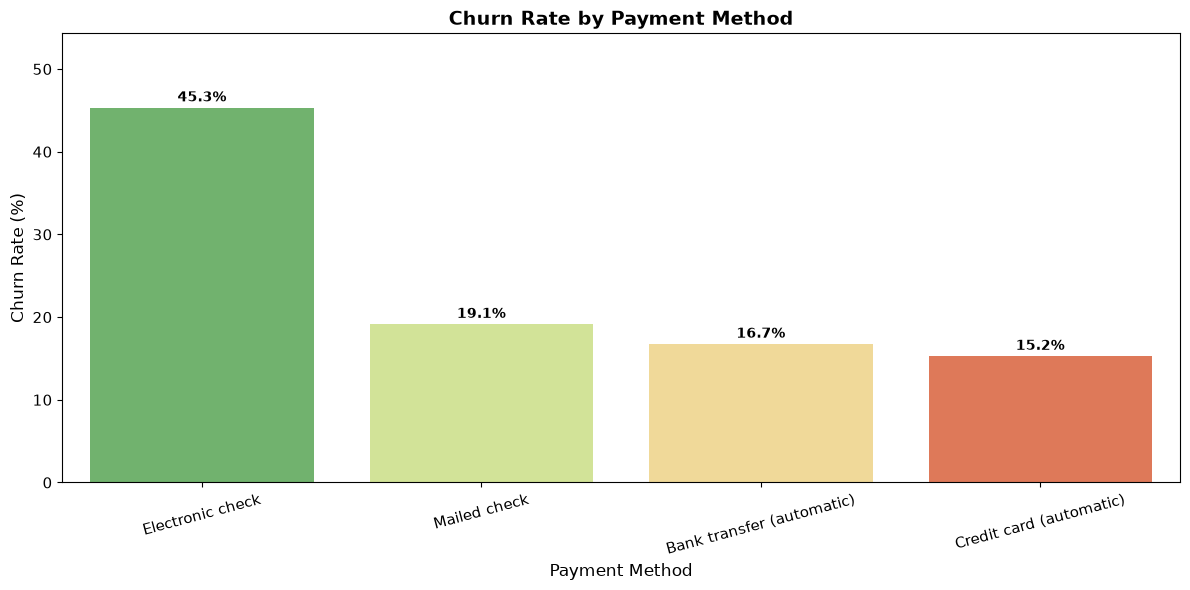

Saved: 06_payment_method_vs_churn.png


In [26]:
fig, ax = plt.subplots(figsize=(12, 6))

pay_churn = telecom.groupby('PaymentMethod')['Churn'].value_counts(normalize=True).mul(100).reset_index(name='Percentage')
pay_churn_yes = pay_churn[pay_churn['Churn'] == 'Yes'].sort_values('Percentage', ascending=False)

sns.barplot(x='PaymentMethod', y='Percentage', data=pay_churn_yes,
            palette='RdYlGn_r', ax=ax)

for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.4,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title('Churn Rate by Payment Method', fontsize=14, fontweight='bold')
ax.set_xlabel('Payment Method', fontsize=12)
ax.set_ylabel('Churn Rate (%)', fontsize=12)
ax.tick_params(axis='x', rotation=15)
ax.set_ylim(0, pay_churn_yes['Percentage'].max() * 1.2)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, '06_payment_method_vs_churn.png'), dpi=EXPORT_DPI, bbox_inches='tight')
plt.show()
print("Saved: 06_payment_method_vs_churn.png")

**Interpretation:**  
- **What the graph shows:** Churn rate across four payment methods.  
- **Pattern observed:** **Electronic check** users have the highest churn rate (~45%), while automated methods (Credit card, Bank transfer) show significantly lower churn (~15–16%).  
- **Why it matters:** Automated payment methods correlate with higher commitment and stickiness. Encouraging customers to switch from electronic checks to auto-pay could be a simple but effective retention strategy.

### 5.10 Senior Citizen vs Churn

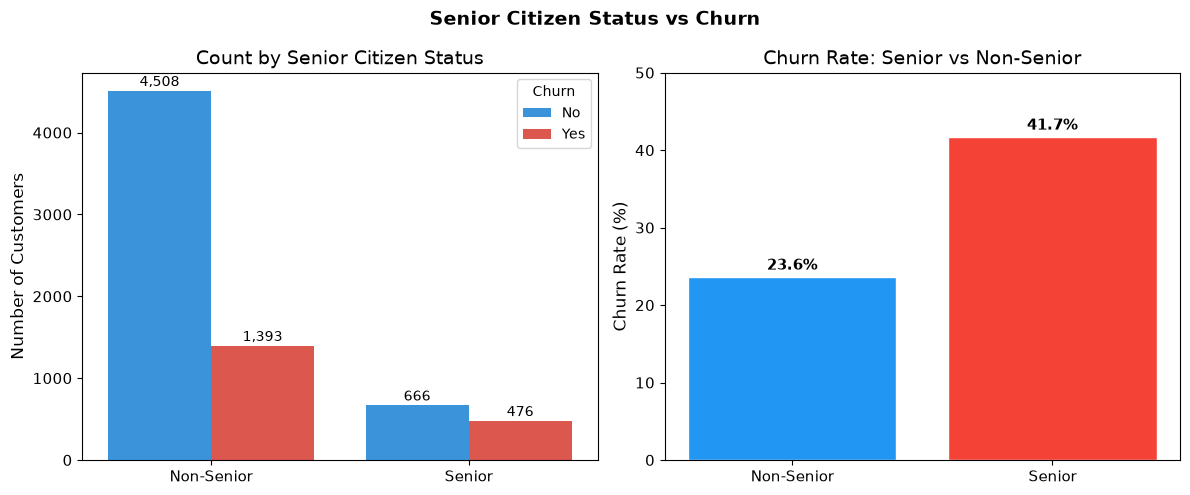

Saved: 07_senior_citizen_vs_churn.png


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Senior Citizen Status vs Churn', fontsize=14, fontweight='bold')

telecom_sc = telecom.copy()
telecom_sc['SeniorCitizen_Label'] = telecom_sc['SeniorCitizen'].map({0: 'Non-Senior', 1: 'Senior'})

sns.countplot(x='SeniorCitizen_Label', hue='Churn', data=telecom_sc, ax=axes[0], palette=PALETTE)
for bar in axes[0].patches:
    h = bar.get_height()
    if h > 0:
        axes[0].text(bar.get_x() + bar.get_width()/2, h + 20, f'{int(h):,}',
                     ha='center', va='bottom', fontsize=10)
axes[0].set_title('Count by Senior Citizen Status')
axes[0].set_xlabel('')
axes[0].set_ylabel('Number of Customers')
axes[0].legend(title='Churn')

sc_rates = [telecom[telecom['SeniorCitizen'] == s]['Churn'].eq('Yes').mean() * 100 for s in [0, 1]]
axes[1].bar(['Non-Senior', 'Senior'], sc_rates, color=['#2196F3', '#F44336'], edgecolor='white')
for i, rate in enumerate(sc_rates):
    axes[1].text(i, rate + 0.5, f'{rate:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[1].set_title('Churn Rate: Senior vs Non-Senior')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_ylim(0, max(sc_rates) * 1.2)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, '07_senior_citizen_vs_churn.png'), dpi=EXPORT_DPI, bbox_inches='tight')
plt.show()
print("Saved: 07_senior_citizen_vs_churn.png")

**Interpretation:**  
- **Pattern observed:** Senior citizens churn at approximately **41%**, versus ~24% for non-seniors — nearly double the rate.  
- **Why it matters:** Senior customers may face digital accessibility challenges or pricing strain. Tailored support programs and senior-friendly plans could significantly reduce this segment's churn.

### 5.11 Gender vs Churn

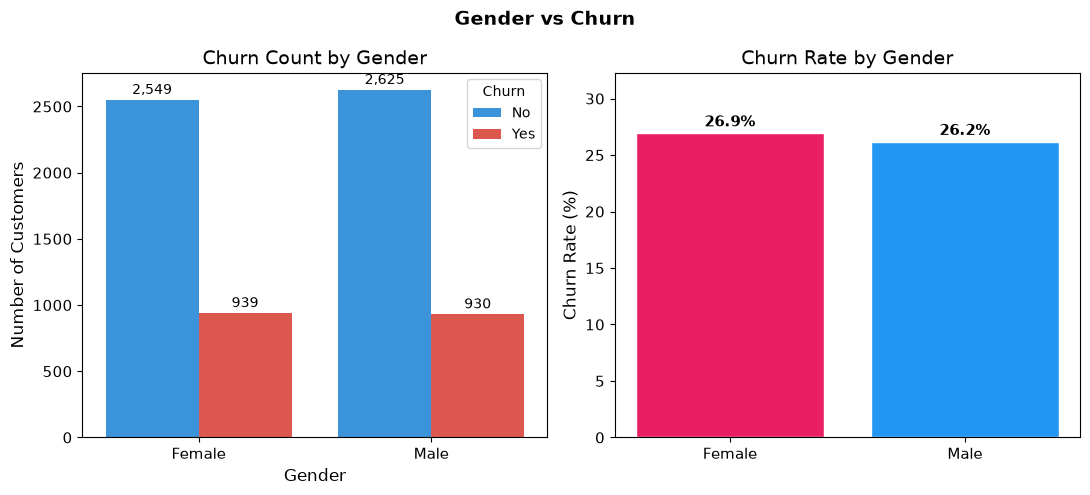

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle('Gender vs Churn', fontsize=14, fontweight='bold')

sns.countplot(x='gender', hue='Churn', data=telecom, ax=axes[0], palette=PALETTE)
for bar in axes[0].patches:
    h = bar.get_height()
    if h > 0:
        axes[0].text(bar.get_x() + bar.get_width()/2, h + 20, f'{int(h):,}',
                     ha='center', va='bottom', fontsize=10)
axes[0].set_title('Churn Count by Gender')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Number of Customers')
axes[0].legend(title='Churn')

gender_rates = [telecom[telecom['gender'] == g]['Churn'].eq('Yes').mean() * 100 for g in ['Female', 'Male']]
axes[1].bar(['Female', 'Male'], gender_rates, color=['#E91E63', '#2196F3'], edgecolor='white')
for i, rate in enumerate(gender_rates):
    axes[1].text(i, rate + 0.3, f'{rate:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[1].set_title('Churn Rate by Gender')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_ylim(0, max(gender_rates) * 1.2)

plt.tight_layout()
plt.show()

**Interpretation:**  
- **Pattern observed:** Male and Female churn rates are nearly identical (~26–27%). Gender shows **minimal predictive power** for churn.  
- **Why it matters:** This confirms that gender alone is not a meaningful predictor. The model should focus on behavioral and service factors rather than demographic gender.

### 5.12 Tenure Distribution by Churn (Histogram)

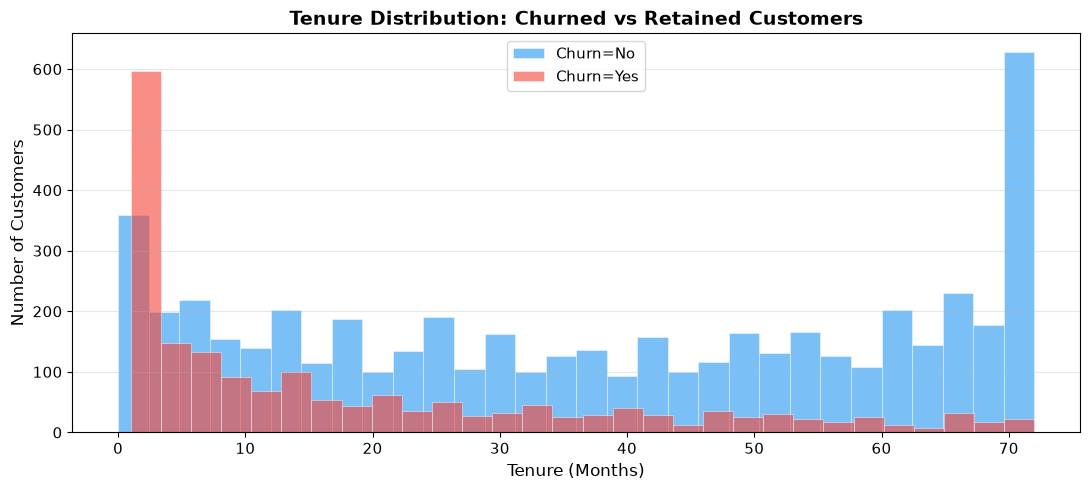

Saved: 08_tenure_distribution.png


In [29]:
fig, ax = plt.subplots(figsize=(11, 5))

for label, color in [('No', '#2196F3'), ('Yes', '#F44336')]:
    subset = telecom[telecom['Churn'] == label]['tenure']
    ax.hist(subset, bins=30, alpha=0.6, color=color, label=f'Churn={label}',
            edgecolor='white', linewidth=0.5)

ax.set_title('Tenure Distribution: Churned vs Retained Customers', fontsize=14, fontweight='bold')
ax.set_xlabel('Tenure (Months)', fontsize=12)
ax.set_ylabel('Number of Customers', fontsize=12)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, '08_tenure_distribution.png'), dpi=EXPORT_DPI, bbox_inches='tight')
plt.show()
print("Saved: 08_tenure_distribution.png")

**Interpretation:**  
- **Pattern observed:** Churned customers are heavily clustered in the **0–12 month tenure range**, while retained customers are more uniformly distributed across all tenures.  
- **Why it matters:** This bimodal pattern among churners (heavy at the start) confirms that onboarding and early-stage engagement are the most critical retention windows.

### 5.13 Paperless Billing vs Churn

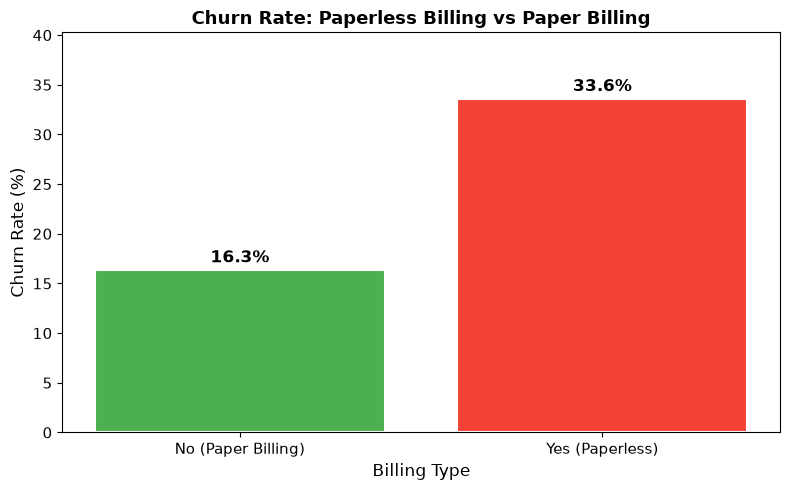

In [30]:
fig, ax = plt.subplots(figsize=(8, 5))

pb_rates = [telecom[telecom['PaperlessBilling'] == pb]['Churn'].eq('Yes').mean() * 100
            for pb in ['No', 'Yes']]
ax.bar(['No (Paper Billing)', 'Yes (Paperless)'], pb_rates,
       color=['#4CAF50', '#F44336'], edgecolor='white', linewidth=1.5)
for i, rate in enumerate(pb_rates):
    ax.text(i, rate + 0.4, f'{rate:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_title('Churn Rate: Paperless Billing vs Paper Billing', fontsize=13, fontweight='bold')
ax.set_xlabel('Billing Type', fontsize=12)
ax.set_ylabel('Churn Rate (%)', fontsize=12)
ax.set_ylim(0, max(pb_rates) * 1.2)

plt.tight_layout()
plt.show()

**Interpretation:**  
- **Pattern observed:** Paperless billing customers churn at ~33%, compared to ~16% for paper billing customers.  
- **Why it matters:** Paperless billing removes the physical touchpoint that keeps customers reminded of their service. Digital-only accounts are easier to cancel without human interaction.

---
## Section 7: EDA Summary

### Key Findings from EDA

| Factor | Observation | Business Impact |
|---|---|---|
| **Tenure** | Short-tenure customers churn most (median ~10 months) | Critical first-year retention period |
| **Contract Type** | Month-to-month churn ~42% vs Two-year ~3% | Contract lock-in is the strongest defense |
| **Internet Service** | Fiber optic churns ~42% — higher than DSL | Service quality issues in premium segment |
| **Payment Method** | Electronic check: ~45% churn; Auto-pay: ~15–16% | Auto-payment enrollment reduces churn |
| **Monthly Charges** | Churned customers pay ~$80 median vs $64 for retained | High billing without perceived value = churn |
| **Senior Citizens** | Seniors churn at ~41% vs ~24% for non-seniors | Accessibility and pricing barriers |
| **Paperless Billing** | Paperless: ~33% churn vs paper: ~16% | Reduced physical touchpoints lead to easier exit |
| **Gender** | Near-identical churn rates (~26–27%) | Not a meaningful churn predictor |

### Transition to Feature Engineering and Modeling

In **Notebook 2**, we will:
1. Preprocess the dataset (type conversion, encoding, scaling)
2. Apply train-test split (70:30)
3. Use **Recursive Feature Elimination (RFE)** to select the top 15 features
4. Build an iterative **Statsmodels GLM Binomial** model removing high-VIF features
5. Determine the optimal decision threshold using the Sensitivity/Specificity plot
6. Evaluate performance on the held-out test set
7. Analyze feature impact and generate business recommendations